### Laboratorium 3 - zadania

In [1]:
import os

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.segmentation import mark_boundaries, slic

#### Zadanie 1

Dane są obrazy `tabby` i `caries` ([źródło](https://universe.roboflow.com/niu-workespeis/caries-xlrql/dataset/2)). Wykonaj dla nich segmentację przy użyciu algorytmu SLIC. Celem jest uzyskanie **jednolitych**  superpikseli, a więc zawierających tylko fragmenty obiektów lub tylko tła (a nie jednego i drugiego naraz). Przeanalizuj zachowanie algorytmu dla różnej liczby superpikseli i parametru sigma.

Zwróć uwagę, że wynikiem działania scikitowej implementacji SLIC - [`skimage.segmentation.slic`](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.slic) - (podobnie jak wielu innych algorytmów klasyfikacyjnych) jest obraz typu `np.int64` przyporządkowujący każdemu pikselowi obrazu wejściowego indeks superpiksela. Takiej reprezentacji oczekuje też funkcja [`mark_boundaries`](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.mark_boundaries).

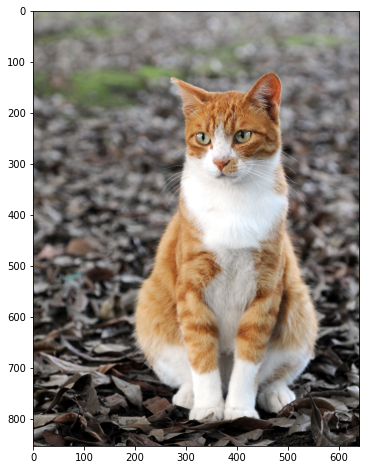

In [2]:
_ = cv2.imread('tabby.jpg')[..., ::-1]
tabby = cv2.resize(_, dsize=None, fx=0.3, fy=0.3)
plt.subplots(1,1,figsize=(8,8))[1].imshow(tabby);

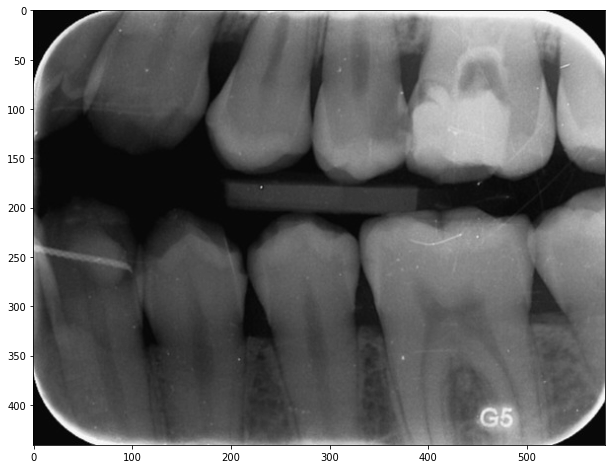

In [3]:
caries = cv2.imread('roboflow-caries-117.jpg')[..., 0]
plt.subplots(1,1,figsize=(12,8))[1].imshow(caries, cmap='gray');

#### Zadanie 2

Wykonaj segmentację wododziałową dla obrazów `tabby` i `caries` za pomocą funkcji [`cv2.watershed`](https://docs.opencv.org/4.x/d3/d47/group__imgproc__segmentation.html#ga3267243e4d3f95165d55a618c65ac6e1). Implementacja OpenCV przyjmuje dwa argumenty: obraz wejściowy (8-bit, 3 kanały) i obraz wyjściowy (32-bit, 1 kanał).

Uwaga: obraz wyjściowy musi zawierać oznaczenia początkowe segmentów (_markery_) - to znaczy, że musisz zacząć od przygotowania macierzy markerów. Poprawnie przygotowana macierz zawiera $N$ markerów, tj. pikseli oznaczonych liczbami całkowitymi od 1 do $N$, a wartość pozostałych pikseli wynosi 0. Piksele zerowe zostaną przyporządkowane do grup dookoła markerów.

Sugerowane metody przygotowania markerów (wybierz dwie i porównaj):
* równomierna siatka
* lokalne minima jasności
* manualnie wybrane centra (_segmentacja interaktywna_)

In [ ]:
markers = np.zeros_like(tabby[..., 0], dtype=np.int32)
# TODO: przygotowanie markerów
# ...
# ...
cv2.watershed(tabby, markers)
plt.imshow(mark_boundaries(tabby, markers))

---

#### Zadanie dodatkowe (dla chętnych, bez oceny)

Dla obrazu `tabby` wykonaj post-processing wybranej metody segmentacji by uzyskać dwa jednorodne obszary: jeden zawierający wyłącznie kota, drugi zawierający wyłącznie tło.

Można to zadanie potraktować jako binaryzację na poziomie superpikseli i zrealizować je za pomocą progowania. 
Można też potraktować je jako klasteryzację superpikseli i wykorzystać np. [`cv2.kmeans`](https://docs.opencv.org/4.x/d5/d38/group__core__cluster.html#ga9a34dc06c6ec9460e90860f15bcd2f88).  
Niezależnie od wybranej ścieżki, konieczne będzie:
1. dobranie odpowiednich (czyli jakich?) parametrów algorytmu segmentacji,
2. opisanie każdego z superpikseli za pomocą jakiejś *cechy/cech* (jakich?), opisującej semantykę rejonów, tak aby na tej podstawie dokonać klasyfikacji.

In [ ]:
# zacznij od przygotowania macierzy wejściowej (data) reprezentującej superpiksele jako punkty danych